In [3]:
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

from dataset.singlecell import SingleCellDataset
from models.classifier3 import Classifier


exp_dir = "/home/lagandua/projects/sven/pineapple/exp/classifier/2024-07-03/11-51-05"

project_dir = "/home/lagandua/projects/sven/pineapple"
model_path = f"{exp_dir}/model.pth"
label_to_idx_path = f"{exp_dir}/label_to_index.json"
data_name = "val_high_10_min2K"
val_path = f"{project_dir}/data/sven_classes_new/{data_name}.npz"
out_dir = f"{project_dir}/exp/plots/classifier/"
os.makedirs(out_dir, exist_ok=True)
comment = ""
device = 'cuda:0'

In [4]:
label_to_index = json.load(open(label_to_idx_path))

In [5]:
val_dataset = SingleCellDataset(val_path)
val_dataset.label_to_index = label_to_index
val_dataset.label_indices = [val_dataset.label_to_index[label] for label in val_dataset.labels]
val_dataloader = torch.utils.data.DataLoader(
        val_dataset, batch_size=64, shuffle=True
    )

In [6]:
input_size = val_dataset.data.shape[-1]
num_classes = len(val_dataset.label_to_index)
hidden_size = 1024
model = Classifier(input_size, hidden_size, num_classes).to(device)
model.load_state_dict(torch.load(model_path))
model.eval()

Classifier(
  (fc1): Linear(in_features=6143, out_features=1024, bias=True)
  (relu1): ReLU()
  (fc3): Linear(in_features=1024, out_features=13, bias=True)
)

In [7]:
val_reps = []
pred_labels = []
true_labels = []
with torch.no_grad():
    for val_inputs, val_targets in val_dataloader:
        val_inputs = val_inputs.to(device).float()
        val_outputs = model(val_inputs)
        val_reps.extend(model(val_inputs, only_representations=True).cpu().numpy().tolist())
        _, predicted = torch.max(val_outputs.data, 1)
        pred_labels.extend(predicted.cpu().numpy().tolist())
        true_labels.extend(val_targets.tolist())

In [8]:
from sklearn.metrics import classification_report
print(classification_report(true_labels, pred_labels, target_names=list(val_dataset.label_to_index.keys())))

                     precision    recall  f1-score   support

            B Cells       0.97      0.96      0.97      4771
  Cytotoxic T cells       0.84      0.88      0.86      5616
                 DC       0.79      0.45      0.58       274
            HSC/MPP       0.46      0.38      0.42       257
     Helper T cells       0.86      0.92      0.89      8027
                ILC       0.89      0.86      0.88      3780
Innate-like T cells       0.67      0.63      0.65      1179
        Macrophages       0.96      0.93      0.94      2459
         Mast Cells       0.97      0.88      0.92       359
          Monocytes       0.92      0.92      0.92      2363
       Plasma cells       0.95      0.94      0.94       914
 Regulatory T cells       0.79      0.65      0.71      1198
            T cells       0.47      0.35      0.40       683

           accuracy                           0.87     31880
          macro avg       0.81      0.75      0.77     31880
       weighted avg   

In [9]:
index_to_label = {v: k for k, v in val_dataset.label_to_index.items()} # Useful for plot legend

In [10]:
val_reps = np.array(val_reps)
count = len(val_reps)

# Embeddings
embeddings = np.copy(val_reps[:count])

# Corresponding class labels
labels = np.array(true_labels)[: count]

In [11]:
import umap

# Initialize UMAP model
umap_model = umap.UMAP(n_neighbors=15, n_components=2, metric='euclidean')

# Fit and transform the embeddings
umap_embeddings = umap_model.fit_transform(embeddings)

/home/lagandua/miniforge3/envs/sven/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_398009/3200072385.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(umap_embeddings[labels == l, 0], umap_embeddings[labels == l, 1], s=5, c=colours[l]) for l in set(labels)]


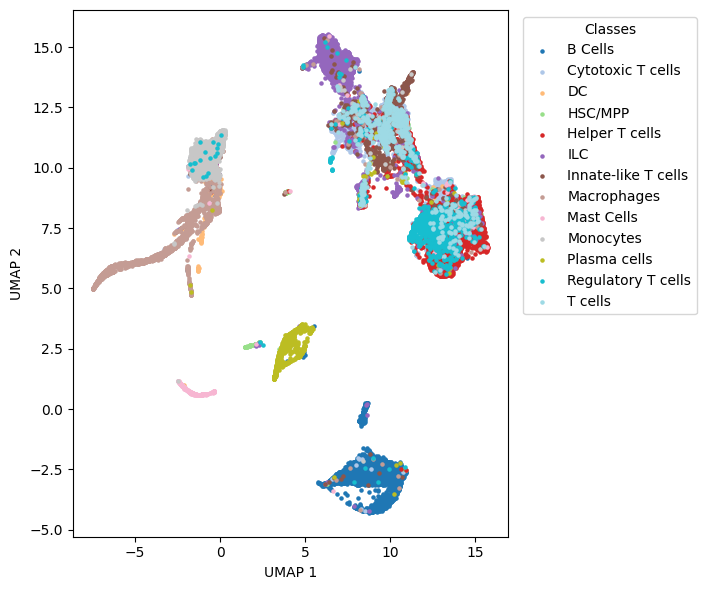

In [12]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(umap_embeddings[labels == l, 0], umap_embeddings[labels == l, 1], s=5, c=colours[l]) for l in set(labels)]

custom_labels = [index_to_label[lbl] for lbl in set(labels)]  # Map to custom label names

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.45, 1.0))

# plt.title(str(val_dataset.label_to_index))
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.tight_layout()
plt.savefig(f"{out_dir}/umap-{hidden_size}-{data_name}-{comment}.png")
plt.show()

In [13]:
from sklearn.manifold import TSNE

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(embeddings)

/tmp/ipykernel_398009/2053549558.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=5, c=colours[l]) for l in set(labels)]


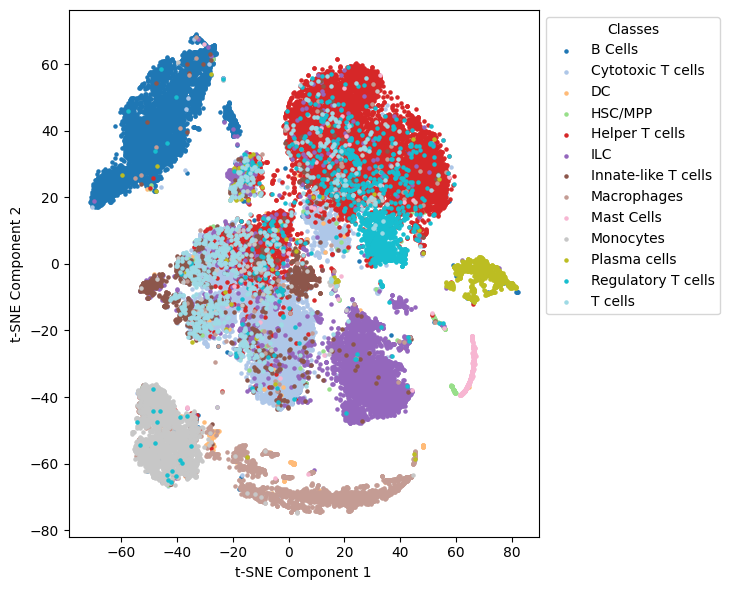

In [14]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=5, c=colours[l]) for l in set(labels)]
custom_labels = [index_to_label[lbl] for lbl in set(labels)]  # Map to custom label names

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.4, 1))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
plt.savefig(f"{out_dir}/t-SNE-{hidden_size}-{data_name}-{comment}.png")
plt.show()